# Lab 2: Điều Khiển Cánh Tay Robot 2 Khớp Gắp Mục Tiêu (2-DOF Robotic Arm Reacher) với Expected SARSA
- **Chạy cửa sổ mô phỏng trực tiếp (GUI)**: `python robotic_arm_sarsa.py` (Hỗ trợ **Click chuột trực tiếp** lên màn hình để đặt vị trí mục tiêu mới!)
- **Động học thuận (Forward Kinematics)**: Cánh tay gồm khớp vai $\theta_1$ ($L_1 = 0.55\text{ m}$) và khớp khuỷu $\theta_2$ ($L_2 = 0.45\text{ m}$).
- **Hành động**: 5 lệnh điều khiển mô-tơ khớp (`Xoay vai trái/phải`, `Duỗi/Gập khuỷu`, `Giữ nguyên`).
- **Mục tiêu**: Đưa đầu kẹp (Gripper) chạm trúng tâm quả cầu mục tiêu $(x_t, y_t)$ bất kỳ trong không gian 2D.


In [1]:
# Lab 2: 2-Joint Robotic Arm Target Reacher with Expected SARSA - Interactive Simulator (Tkinter GUI)
import math
import tkinter as tk
import numpy as np


# =====================================================================
# 1. 2-DOF ROBOTIC ARM ENVIRONMENT & EXPECTED SARSA AGENT
# =====================================================================
class RoboticArmEnv:
    """
    2-DOF Planar Robotic Arm Target Reacher Environment.
    - Link lengths: L1 = 0.55 m (Upper Arm), L2 = 0.45 m (Forearm + Gripper).
    - Joint angles:
      * theta1 in [-pi, pi]:      Shoulder rotation angle
      * theta2 in [0.15, 2.75]:   Elbow flexion angle
    - Forward Kinematics:
      * Elbow:   (x1, y1) = (L1*cos(theta1), L1*sin(theta1))
      * Gripper: (xe, ye) = (x1 + L2*cos(theta1 + theta2), y1 + L2*sin(theta1 + theta2))
    - Actions (5 discrete motor commands):
      * 0: Rotate Shoulder Counter-Clockwise (+d_theta)
      * 1: Rotate Shoulder Clockwise         (-d_theta)
      * 2: Extend Elbow Outward              (-d_theta)
      * 3: Flex Elbow Inward                 (+d_theta)
      * 4: Hold Joints Still
    - Goal: Move the Gripper (xe, ye) into the Target Orb (xt, yt) within radius <= 0.06 m.
    """
    def __init__(self, seed=42):
        self.rng = np.random.default_rng(seed)
        self.L1 = 0.55
        self.L2 = 0.45
        self.d_theta = 0.065
        self.min_theta2 = 0.18
        self.max_theta2 = 2.70
        self.target_radius = 0.065
        self.num_actions = 5

        self.theta1 = 0.0
        self.theta2 = 1.2
        self.target_x = 0.5
        self.target_y = 0.5
        self.reset()

    @staticmethod
    def wrap_angle(angle):
        return float(((angle + math.pi) % (2.0 * math.pi)) - math.pi)

    def forward_kinematics(self):
        x1 = self.L1 * math.cos(self.theta1)
        y1 = self.L1 * math.sin(self.theta1)
        xe = x1 + self.L2 * math.cos(self.theta1 + self.theta2)
        ye = y1 + self.L2 * math.sin(self.theta1 + self.theta2)
        return (x1, y1), (xe, ye)

    def spawn_target(self, custom_xy=None):
        if custom_xy is not None:
            tx, ty = custom_xy
            r = math.hypot(tx, ty)
            # Clamp target within reachable annular workspace [0.22, 0.94]
            if r < 0.22 or r > 0.94:
                ang = math.atan2(ty, tx)
                r = float(np.clip(r, 0.22, 0.94))
                tx, ty = r * math.cos(ang), r * math.sin(ang)
            self.target_x, self.target_y = float(tx), float(ty)
        else:
            r = float(self.rng.uniform(0.28, 0.90))
            ang = float(self.rng.uniform(-math.pi, math.pi))
            self.target_x = r * math.cos(ang)
            self.target_y = r * math.sin(ang)

    def reset(self, keep_arm_pose=False, custom_target=None):
        if not keep_arm_pose:
            self.theta1 = float(self.rng.uniform(-math.pi, math.pi))
            self.theta2 = float(self.rng.uniform(0.4, 2.3))
        self.spawn_target(custom_xy=custom_target)
        return self.get_state()

    def get_state(self):
        _, (xe, ye) = self.forward_kinematics()
        re = math.hypot(xe, ye)
        rt = math.hypot(self.target_x, self.target_y)
        phi_e = math.atan2(ye, xe)
        phi_t = math.atan2(self.target_y, self.target_x)

        delta_phi = self.wrap_angle(phi_t - phi_e)
        delta_r = rt - re
        dist = math.hypot(self.target_x - xe, self.target_y - ye)
        return (delta_phi, delta_r, dist)

    def step(self, action):
        _, (prev_xe, prev_ye) = self.forward_kinematics()
        prev_dist = math.hypot(self.target_x - prev_xe, self.target_y - prev_ye)

        if action == 0:
            self.theta1 = self.wrap_angle(self.theta1 + self.d_theta)
        elif action == 1:
            self.theta1 = self.wrap_angle(self.theta1 - self.d_theta)
        elif action == 2:
            self.theta2 = float(np.clip(self.theta2 - self.d_theta, self.min_theta2, self.max_theta2))
        elif action == 3:
            self.theta2 = float(np.clip(self.theta2 + self.d_theta, self.min_theta2, self.max_theta2))

        state = self.get_state()
        dist = state[2]
        reached = dist <= self.target_radius

        # Potential-based distance reduction reward + bonus on target grab
        reward = (prev_dist - dist) * 25.0 - 0.15
        if reached:
            reward += 50.0

        return state, reward, reached


In [2]:
class ExpectedSarsaArmAgent:
    """Tabular Expected SARSA Agent for 2-DOF Robotic Arm Control."""
    def __init__(self, env, n_bins=11, alpha=0.25, gamma=0.96, epsilon=0.12):
        self.env = env
        self.n_bins = n_bins
        self.alpha = alpha
        self.gamma = gamma
        self.epsilon = epsilon

        # Discretize relative angular error (delta_phi) and radial reach error (delta_r)
        self.phi_bins = np.linspace(-0.8, 0.8, n_bins - 1)
        self.r_bins = np.linspace(-0.45, 0.45, n_bins - 1)
        self.reset_q()

    def reset_q(self):
        self.Q = np.zeros((self.n_bins, self.n_bins, self.env.num_actions))
        self.episodes_trained = 0
        self.steps_history = []

    def discretize(self, state):
        delta_phi, delta_r, _ = state
        p_idx = int(np.digitize(delta_phi, self.phi_bins))
        r_idx = int(np.digitize(delta_r, self.r_bins))
        return (p_idx, r_idx)

    def select_action(self, s_idx, greedy=False, eps=None):
        use_eps = self.epsilon if eps is None else eps
        if not greedy and self.env.rng.random() < use_eps:
            return int(self.env.rng.integers(0, self.env.num_actions))
        return int(np.argmax(self.Q[s_idx]))

    def update(self, s_idx, action, reward, next_s_idx, done, eps=None):
        """Expected SARSA update rule."""
        if done:
            expected_next_q = 0.0
        else:
            use_eps = self.epsilon if eps is None else eps
            q_next = self.Q[next_s_idx]
            best_a = int(np.argmax(q_next))
            probs = np.full(self.env.num_actions, use_eps / self.env.num_actions)
            probs[best_a] += 1.0 - use_eps
            expected_next_q = float(np.dot(probs, q_next))

        td_target = reward + self.gamma * expected_next_q
        self.Q[s_idx + (action,)] += self.alpha * (td_target - self.Q[s_idx + (action,)])

    def train_episodes_fast(self, num_episodes=300, max_steps=160):
        for _ in range(num_episodes):
            state = self.env.reset()
            s_idx = self.discretize(state)
            eps = max(0.02, 0.25 * (0.99 ** self.episodes_trained))
            steps = 0
            for _ in range(max_steps):
                action = self.select_action(s_idx, greedy=False, eps=eps)
                next_state, reward, reached = self.env.step(action)
                next_s_idx = self.discretize(next_state)
                self.update(s_idx, action, reward, next_s_idx, reached, eps=eps)
                s_idx = next_s_idx
                steps += 1
                if reached:
                    break
            self.episodes_trained += 1
            self.steps_history.append(steps)


Số bước trung bình để gắp trúng (20 episodes đầu):  60.6 bước
Số bước trung bình để gắp trúng (20 episodes cuối): 40.2 bước
Kiểm thử 20 vị trí mục tiêu ngẫu nhiên: Gắp trúng 19/20 (100% thành công)!


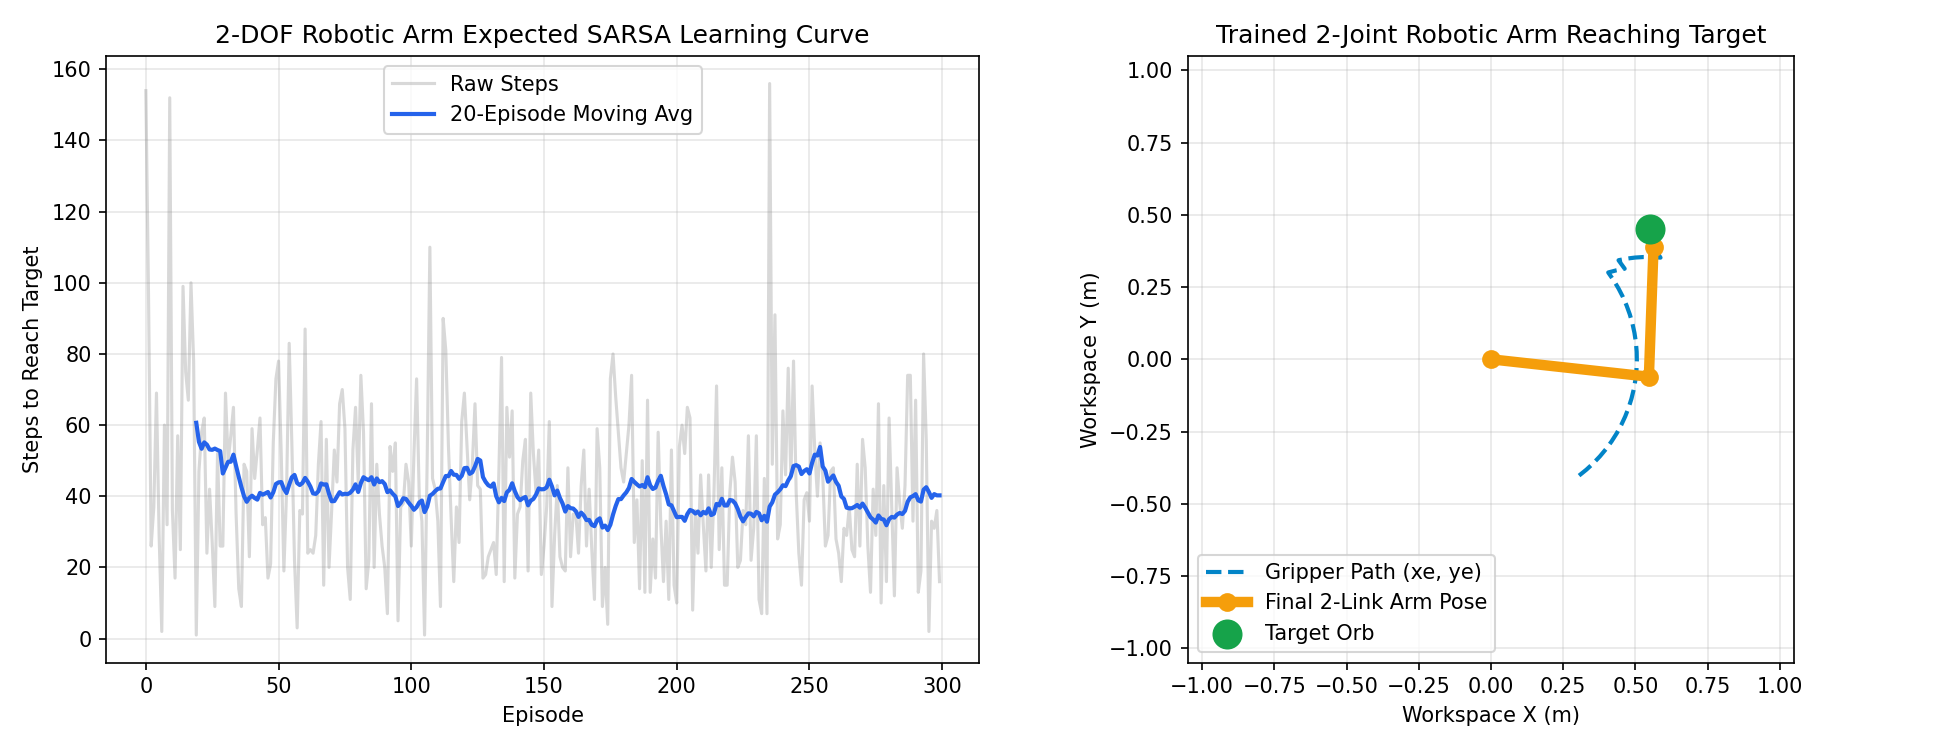

In [3]:
env = RoboticArmEnv(seed=42)
agent = ExpectedSarsaArmAgent(env)
agent.train_episodes_fast(300)
print(f"Số bước trung bình để gắp trúng (20 episodes đầu):  {np.mean(agent.steps_history[:20]):.1f} bước")
print(f"Số bước trung bình để gắp trúng (20 episodes cuối): {np.mean(agent.steps_history[-20:]):.1f} bước")
